# 15. Ridge Regression: K-Fold Cross-Validation for Selecting λ

**Project:** Ridge Regression and Multicollinearity  
**Dataset:** UCI Real Estate Valuation (414 observations)  
**Target:** `Y house price of unit area`

## Objective

Select the Ridge regularization parameter λ using manually implemented *k*-fold cross-validation with NumPy and pandas. The same logarithmic λ grid used in Notebook 14 is retained. Within every fold, predictor means and standard deviations are calculated using **only that fold's training data**. This prevents preprocessing leakage.

The intercept is included in the model but is not penalized. The selection criterion is the lowest mean validation MSE across folds. After selecting λ, the final Ridge model is refitted using the complete dataset.

> Cross-validation performance is a model-selection estimate, not an independent final test-set result. Notebook 16 can provide a separate final evaluation if required.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

RANDOM_STATE = 42
N_SPLITS = 5


In [3]:
results = Path("../../results/implementation")
figures = results / "figures"
tables = results / "tables"

In [4]:
df = pd.read_csv("../../data/processed/real_estate_data_updated.csv")

df.head()

,X1 transaction year,X1 transaction month,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,2012,December,32.0,84.87882,10,24.98298,121.54024,37.9
1,2012,December,19.5,306.59470,9,24.98034,121.53951,42.2
2,2013,August,13.3,561.98450,5,24.98746,121.54391,47.3
3,2013,July,13.3,561.98450,5,24.98746,121.54391,54.8
4,2012,November,5.0,390.56840,5,24.97937,121.54245,43.1


In [5]:
target_column = "Y house price of unit area"
numerical_features = [
    "X2 house age",
    "X3 distance to the nearest MRT station",
    "X4 number of convenience stores",
    "X5 latitude",
    "X6 longitude",
]
categorical_features = ["X1 transaction month"]

required_columns = numerical_features + categorical_features + [target_column]
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")

model_data = df[required_columns].copy()
model_data = model_data.dropna().reset_index(drop=True)

X_numerical = model_data[numerical_features].astype(float)
X_categorical = pd.get_dummies(
    model_data[categorical_features].astype(str),
    columns=categorical_features,
    drop_first=True,
    dtype=float,
)

X_df = pd.concat([X_numerical, X_categorical], axis=1)
y = model_data[target_column].to_numpy(dtype=float)
feature_names = X_df.columns.tolist()
X = X_df.to_numpy(dtype=float)

print("Observations used:", len(y))
print("Number of predictors:", X.shape[1])
print("Design matrix before intercept:", X.shape)
print("Target:", target_column)
print("Features:", feature_names)

Observations used: 414
Number of predictors: 16
Design matrix before intercept: (414, 16)
Target: Y house price of unit area
Features: ['X2 house age', 'X3 distance to the nearest MRT station', 'X4 number of convenience stores', 'X5 latitude', 'X6 longitude', 'X1 transaction month_August', 'X1 transaction month_December', 'X1 transaction month_February', 'X1 transaction month_January', 'X1 transaction month_July', 'X1 transaction month_June', 'X1 transaction month_March', 'X1 transaction month_May', 'X1 transaction month_November', 'X1 transaction month_October', 'X1 transaction month_September']


In [6]:
# Retain the same logarithmic range used in Notebook 14.
# define lambda grid

lambda_values = np.logspace(-4, 4, 200)

print("Number of lambda values:", len(lambda_values))
print("Minimum lambda:", lambda_values.min())
print("Maximum lambda:", lambda_values.max())

Number of lambda values: 200
Minimum lambda: 0.0001
Maximum lambda: 10000.0


In [7]:
# implement shuffled k-fold splitting using numpy

def make_kfold_indices(n_samples, n_splits=5, random_state=42):
    """Return reproducible (train_indices, validation_indices) folds."""
    if n_splits < 2 or n_splits > n_samples:
        raise ValueError("n_splits must be between 2 and the number of samples.")

    rng = np.random.default_rng(random_state)
    indices = rng.permutation(n_samples)
    fold_sizes = np.full(n_splits, n_samples // n_splits, dtype=int)
    fold_sizes[: n_samples % n_splits] += 1

    folds = []
    current = 0
    for fold_size in fold_sizes:
        start, stop = current, current + fold_size
        validation_indices = indices[start:stop]
        training_indices = np.concatenate((indices[:start], indices[stop:]))
        folds.append((training_indices, validation_indices))
        current = stop
    return folds

folds = make_kfold_indices(len(y), N_SPLITS, RANDOM_STATE)

for fold_number, (train_idx, validation_idx) in enumerate(folds, start=1):
    print(
        f"Fold {fold_number}: train={len(train_idx)}, "
        f"validation={len(validation_idx)}"
    )

Fold 1: train=331, validation=83
Fold 2: train=331, validation=83
Fold 3: train=331, validation=83
Fold 4: train=331, validation=83
Fold 5: train=332, validation=82


In [8]:
# verify fold coverage

validation_counts = np.zeros(len(y), dtype=int)
for _, validation_idx in folds:
    validation_counts[validation_idx] += 1

assert np.all(validation_counts == 1), "Each observation must appear in validation exactly once."
print("Fold coverage verified: every observation appears in one validation fold.")

Fold coverage verified: every observation appears in one validation fold.


In [9]:
# implement fold wise standardization

def standardize_from_training(X_train, X_validation):
    """Fit scaling parameters on training data and apply them to both sets."""
    means = X_train.mean(axis=0)
    scales = X_train.std(axis=0, ddof=0)
    # Protect against a constant predictor in a particular training fold.
    scales = np.where(scales == 0.0, 1.0, scales)

    X_train_scaled = (X_train - means) / scales
    X_validation_scaled = (X_validation - means) / scales
    return X_train_scaled, X_validation_scaled, means, scales

# Demonstrate the transformation on the first fold.
train_idx, validation_idx = folds[0]
X_train_demo, X_validation_demo, demo_means, demo_scales = standardize_from_training(
    X[train_idx], X[validation_idx]
)
print("Training-fold scaled means (first five):", X_train_demo.mean(axis=0)[:5])
print("Validation-fold scaled shape:", X_validation_demo.shape)

Training-fold scaled means (first five): [-2.28082072e-16  1.83471902e-16  7.58037473e-17  2.59206889e-13
 -3.77721788e-12]
Validation-fold scaled shape: (83, 16)


In [12]:
# define the ridge estimator

def fit_ridge(X_train_scaled, y_train, regularization):
    """Fit Ridge with an unpenalized intercept using a linear solve."""
    n_samples = X_train_scaled.shape[0]
    X_design = np.column_stack((np.ones(n_samples), X_train_scaled))

    penalty = np.eye(X_design.shape[1])
    penalty[0, 0] = 0.0  # Do not penalize the intercept.

    system_matrix = X_design.T @ X_design + regularization * penalty
    rhs = X_design.T @ y_train
    coefficients = np.linalg.solve(system_matrix, rhs)
    return coefficients


def predict_ridge(X_scaled, coefficients):
    X_design = np.column_stack((np.ones(X_scaled.shape[0]), X_scaled))
    return X_design @ coefficients

In [11]:
# define evaluation metrics

def regression_metrics(y_true, y_pred):
    residuals = y_true - y_pred
    mse = np.mean(residuals ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(residuals))
    ss_total = np.sum((y_true - np.mean(y_true)) ** 2)
    ss_residual = np.sum(residuals ** 2)
    r2 = 1.0 - ss_residual / ss_total if ss_total > 0 else np.nan
    return {"MSE": mse, "RMSE": rmse, "MAE": mae, "R2": r2}

<!-- ## 12. Run K-Fold Cross-Validation for Every λ -->

In [14]:
# Run K-Fold Cross-Validation for Every lambda

fold_records = []

for lambda_value in lambda_values:
    for fold_number, (train_idx, validation_idx) in enumerate(folds, start=1):
        X_train_scaled, X_validation_scaled, fold_means, fold_scales = standardize_from_training(
            X[train_idx], X[validation_idx]
        )
        y_train = y[train_idx]
        y_validation = y[validation_idx]

        coefficients = fit_ridge(X_train_scaled, y_train, lambda_value)
        validation_predictions = predict_ridge(X_validation_scaled, coefficients)
        metrics = regression_metrics(y_validation, validation_predictions)

        fold_records.append({
            "Lambda": lambda_value,
            "Fold": fold_number,
            "Training_Size": len(train_idx),
            "Validation_Size": len(validation_idx),
            **metrics,
        })

fold_results = pd.DataFrame(fold_records)
print("Fold-level results shape:", fold_results.shape)
display(fold_results.head())

Fold-level results shape: (1000, 8)


,Lambda,Fold,Training_Size,Validation_Size,MSE,RMSE,MAE,R2
0,0.0001,1,331,83,80.978339,8.998797,7.318383,0.553887
1,0.0001,2,331,83,65.084830,8.067517,5.661820,0.547083
2,0.0001,3,331,83,66.124389,8.131690,6.260093,0.636974
3,0.0001,4,331,83,148.048832,12.167532,6.784913,0.426070
4,0.0001,5,332,82,74.818456,8.649766,6.209865,0.497559


In [15]:
# aggregate cross-validation results

cv_summary = (
    fold_results.groupby("Lambda")[ ["MSE", "RMSE", "MAE", "R2"] ]
    .agg(["mean", "std"])
)
cv_summary.columns = [f"{metric}_{stat}" for metric, stat in cv_summary.columns]
cv_summary = cv_summary.reset_index()

cv_summary = cv_summary.sort_values("Lambda").reset_index(drop=True)
display(cv_summary.head())

,Lambda,MSE_mean,MSE_std,RMSE_mean,RMSE_std,MAE_mean,MAE_std,R2_mean,R2_std
0,0.000100,87.010969,34.740738,9.20306,1.700973,6.447015,0.628722,0.532315,0.077674
1,0.000110,87.010969,34.740738,9.20306,1.700973,6.447015,0.628722,0.532315,0.077674
2,0.000120,87.010968,34.740739,9.20306,1.700973,6.447015,0.628722,0.532315,0.077674
3,0.000132,87.010968,34.740739,9.20306,1.700973,6.447015,0.628723,0.532315,0.077674
4,0.000145,87.010967,34.740740,9.20306,1.700973,6.447015,0.628723,0.532315,0.077674


In [17]:
# select the optimal lambda

best_row = cv_summary.loc[cv_summary["MSE_mean"].idxmin()]
best_lambda = float(best_row["Lambda"])
best_cv_mse = float(best_row["MSE_mean"])

print(f"Selected lambda: {best_lambda:.10g}")
print(f"Minimum mean CV MSE: {best_cv_mse:.6f}")
print(f"Mean CV RMSE at selected lambda: {best_row['RMSE_mean']:.6f}")
print(f"Mean CV MAE at selected lambda: {best_row['MAE_mean']:.6f}")
print(f"Mean CV R² at selected lambda: {best_row['R2_mean']:.6f}")

Selected lambda: 35.29707303
Minimum mean CV MSE: 86.416203
Mean CV RMSE at selected lambda: 9.167386
Mean CV MAE at selected lambda: 6.447812
Mean CV R² at selected lambda: 0.536094


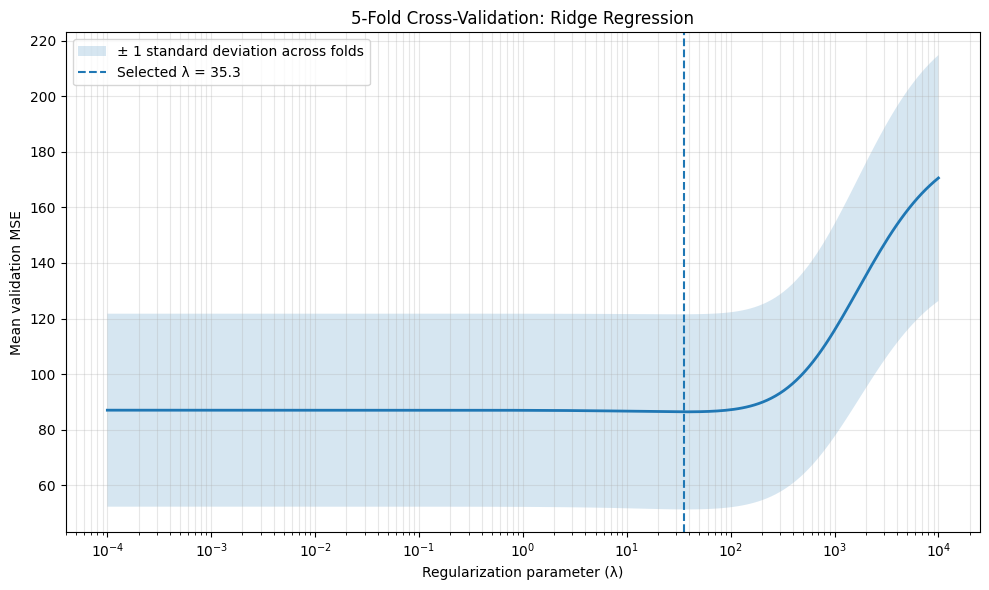

In [18]:
# plot mean cross-validation MSE versus lambda

plt.figure(figsize=(10, 6))
plt.plot(cv_summary["Lambda"], cv_summary["MSE_mean"], linewidth=2)
plt.fill_between(
    cv_summary["Lambda"],
    cv_summary["MSE_mean"] - cv_summary["MSE_std"],
    cv_summary["MSE_mean"] + cv_summary["MSE_std"],
    alpha=0.18,
    label="± 1 standard deviation across folds",
)
plt.axvline(best_lambda, linestyle="--", label=f"Selected λ = {best_lambda:.4g}")
plt.xscale("log")
plt.xlabel("Regularization parameter (λ)")
plt.ylabel("Mean validation MSE")
plt.title("5-Fold Cross-Validation: Ridge Regression")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(figures / "ridge_cv_mse_vs_lambda.png", dpi=300, bbox_inches="tight")
plt.show()

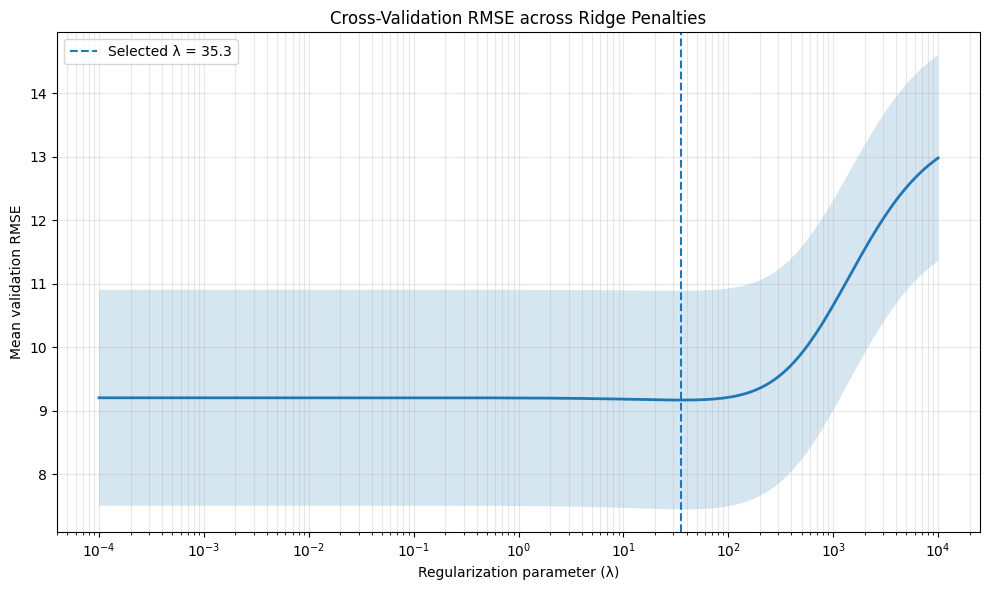

In [19]:
# plot mean cross-validation RMSE versus lambda

plt.figure(figsize=(10, 6))
plt.plot(cv_summary["Lambda"], cv_summary["RMSE_mean"], linewidth=2)
plt.fill_between(
    cv_summary["Lambda"],
    cv_summary["RMSE_mean"] - cv_summary["RMSE_std"],
    cv_summary["RMSE_mean"] + cv_summary["RMSE_std"],
    alpha=0.18,
)
plt.axvline(best_lambda, linestyle="--", label=f"Selected λ = {best_lambda:.4g}")
plt.xscale("log")
plt.xlabel("Regularization parameter (λ)")
plt.ylabel("Mean validation RMSE")
plt.title("Cross-Validation RMSE across Ridge Penalties")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(figures / "ridge_cv_rmse_vs_lambda.png", dpi=300, bbox_inches="tight")
plt.show()

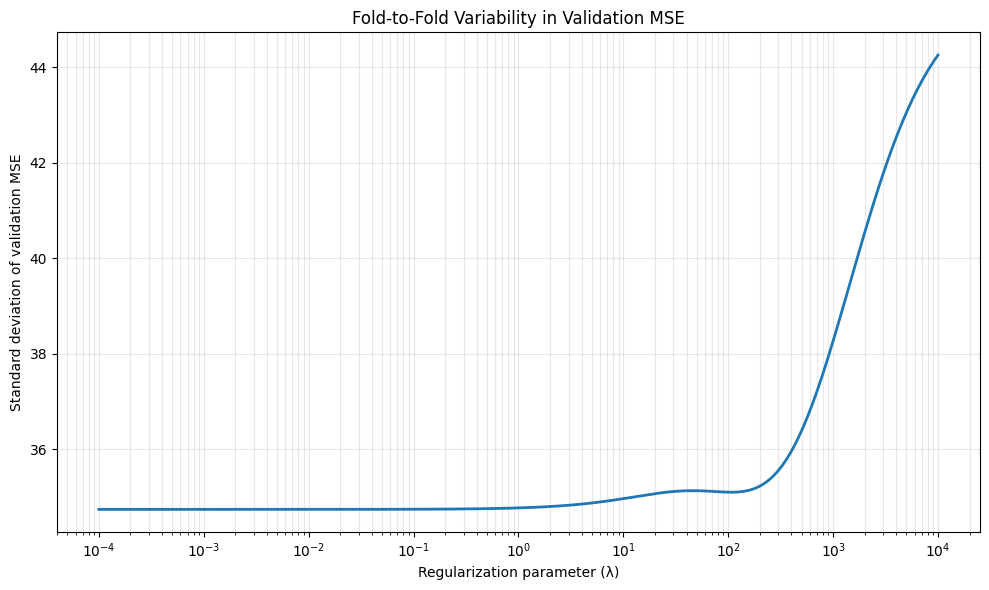

In [20]:
# plot fold-to-fold variablity

plt.figure(figsize=(10, 6))
plt.plot(cv_summary["Lambda"], cv_summary["MSE_std"], linewidth=2)
plt.xscale("log")
plt.xlabel("Regularization parameter (λ)")
plt.ylabel("Standard deviation of validation MSE")
plt.title("Fold-to-Fold Variability in Validation MSE")
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.savefig(figures / "ridge_cv_mse_std_vs_lambda.png", dpi=300, bbox_inches="tight")
plt.show()

In [21]:
# compare selected lambda with nearby grid values

best_position = int(np.argmin(np.abs(lambda_values - best_lambda)))
nearby_positions = range(max(0, best_position - 3), min(len(lambda_values), best_position + 4))
nearby_lambda_summary = cv_summary.iloc[list(nearby_positions)].copy()
display(nearby_lambda_summary)

,Lambda,MSE_mean,MSE_std,RMSE_mean,RMSE_std,MAE_mean,MAE_std,R2_mean,R2_std
135,26.738416,86.437211,35.105039,9.168700,1.721975,6.441788,0.649396,0.535920,0.078994
136,29.331663,86.425937,35.113650,9.168013,1.722449,6.443063,0.649074,0.536002,0.078962
137,32.176418,86.418650,35.120805,9.167559,1.722827,6.445302,0.647525,0.536061,0.078913
138,35.297073,86.416203,35.126381,9.167386,1.723094,6.447812,0.646106,0.536094,0.078843
139,38.720388,86.419576,35.130290,9.167548,1.723239,6.450831,0.644581,0.536095,0.078751
140,42.475716,86.429897,35.132489,9.168109,1.723251,6.454715,0.642808,0.536056,0.078634
141,46.595257,86.448459,35.132987,9.169141,1.723119,6.458881,0.640901,0.535972,0.078491


## 19. Refit the Final Ridge Model on the Complete Dataset

In [22]:
# refit the final ridge model on the complete dataset

# Re-estimate scaling parameters using the complete dataset only after lambda selection.

full_means = X.mean(axis=0)
full_scales = X.std(axis=0, ddof=0)
full_scales = np.where(full_scales == 0.0, 1.0, full_scales)
X_standardized = (X - full_means) / full_scales

final_coefficients = fit_ridge(X_standardized, y, best_lambda)
final_predictions = predict_ridge(X_standardized, final_coefficients)
final_training_metrics = regression_metrics(y, final_predictions)

print("Final Ridge model refitted on all available observations.")
print("Selected lambda:", best_lambda)
display(pd.DataFrame([final_training_metrics], index=["Full-data training"]))

Final Ridge model refitted on all available observations.
Selected lambda: 35.2970730273065


,MSE,RMSE,MAE,R2
Full-data training,75.446725,8.686007,6.057998,0.591494


## 20. Construct the Final Coefficient Table

In [23]:
# construct the final coefficient table

coefficient_names = ["Intercept"] + feature_names
final_coefficient_table = pd.DataFrame({
    "Feature": coefficient_names,
    "Ridge_Coefficient": final_coefficients,
})

display(final_coefficient_table)

,Feature,Ridge_Coefficient
0,Intercept,37.980193
1,X2 house age,-2.842976
2,X3 distance to the nearest MRT station,-4.587994
3,X4 number of convenience stores,3.335464
4,X5 latitude,2.905601
5,X6 longitude,0.632408
6,X1 transaction month_August,0.559131
7,X1 transaction month_December,-0.805886
8,X1 transaction month_February,0.255602
9,X1 transaction month_January,-0.326588


In [25]:
# compare full-data ols and selected ridge coefficients

X_design = np.column_stack((np.ones(len(y)), X_standardized))
ols_coefficients, _, ols_rank, ols_singular_values = np.linalg.lstsq(X_design, y, rcond=None)

coefficient_comparison = pd.DataFrame({
    "Feature": coefficient_names,
    "OLS_Coefficient": ols_coefficients,
    "Ridge_Coefficient": final_coefficients,
})
coefficient_comparison["Absolute_Change"] = np.abs(
    coefficient_comparison["Ridge_Coefficient"] - coefficient_comparison["OLS_Coefficient"]
)
coefficient_comparison["Absolute_Ridge_Coefficient"] = np.abs(
    coefficient_comparison["Ridge_Coefficient"]
)
display(coefficient_comparison)
print("OLS design-matrix rank:", ols_rank)

,Feature,OLS_Coefficient,Ridge_Coefficient,Absolute_Change,Absolute_Ridge_Coefficient
0,Intercept,37.980193,37.980193,1.300293e-12,37.980193
1,X2 house age,-3.103989,-2.842976,2.610133e-01,2.842976
2,X3 distance to the nearest MRT station,-5.650556,-4.587994,1.062562e+00,4.587994
3,X4 number of convenience stores,3.394340,3.335464,5.887591e-02,3.335464
4,X5 latitude,2.888137,2.905601,1.746474e-02,2.905601
5,X6 longitude,-0.186302,0.632408,8.187102e-01,0.632408
6,X1 transaction month_August,0.649505,0.559131,9.037377e-02,0.559131
7,X1 transaction month_December,-0.870451,-0.805886,6.456509e-02,0.805886
8,X1 transaction month_February,0.236571,0.255602,1.903041e-02,0.255602
9,X1 transaction month_January,-0.222263,-0.326588,1.043250e-01,0.326588


OLS design-matrix rank: 17


In [26]:
# compare ols and ridge training metrics

ols_predictions = X_design @ ols_coefficients
ols_training_metrics = regression_metrics(y, ols_predictions)

full_data_comparison = pd.DataFrame([
    {"Model": "OLS", **ols_training_metrics},
    {"Model": f"Ridge (lambda={best_lambda:.6g})", **final_training_metrics},
])
display(full_data_comparison)

print("Note: these are full-data training metrics, not cross-validation estimates.")

,Model,MSE,RMSE,MAE,R2
0,OLS,74.973033,8.658697,6.013422,0.594059
1,Ridge (lambda=35.2971),75.446725,8.686007,6.057998,0.591494


Note: these are full-data training metrics, not cross-validation estimates.


In [27]:
# compare ols and selected ridge using the same cv folds

ols_cv_records = []
for fold_number, (train_idx, validation_idx) in enumerate(folds, start=1):
    X_train_scaled, X_validation_scaled, _, _ = standardize_from_training(
        X[train_idx], X[validation_idx]
    )
    X_train_design = np.column_stack((np.ones(len(train_idx)), X_train_scaled))
    X_validation_design = np.column_stack((np.ones(len(validation_idx)), X_validation_scaled))

    beta_ols, _, _, _ = np.linalg.lstsq(X_train_design, y[train_idx], rcond=None)
    beta_ridge = fit_ridge(X_train_scaled, y[train_idx], best_lambda)

    for model_name, beta in [("OLS", beta_ols), ("Ridge", beta_ridge)]:
        predictions = X_validation_design @ beta
        metrics = regression_metrics(y[validation_idx], predictions)
        ols_cv_records.append({"Model": model_name, "Fold": fold_number, **metrics})

ols_ridge_cv_folds = pd.DataFrame(ols_cv_records)
ols_ridge_cv_summary = (
    ols_ridge_cv_folds.groupby("Model")[["MSE", "RMSE", "MAE", "R2"]]
    .agg(["mean", "std"])
)
ols_ridge_cv_summary.columns = [f"{metric}_{stat}" for metric, stat in ols_ridge_cv_summary.columns]
ols_ridge_cv_summary = ols_ridge_cv_summary.reset_index()
display(ols_ridge_cv_summary)

,Model,MSE_mean,MSE_std,RMSE_mean,RMSE_std,MAE_mean,MAE_std,R2_mean,R2_std
0,OLS,87.010974,34.740735,9.203061,1.700973,6.447015,0.628722,0.532315,0.077674
1,Ridge,86.416203,35.126381,9.167386,1.723094,6.447812,0.646106,0.536094,0.078843


In [28]:
# analyze coefficent shrinkage

coefficient_comparison["Shrinkage_Percent"] = np.where(
    np.abs(coefficient_comparison["OLS_Coefficient"]) > 1e-12,
    100.0 * (
        1.0 - np.abs(coefficient_comparison["Ridge_Coefficient"])
        / np.abs(coefficient_comparison["OLS_Coefficient"])
    ),
    np.nan,
)

ols_norm = np.linalg.norm(ols_coefficients[1:])
ridge_norm = np.linalg.norm(final_coefficients[1:])
print(f"OLS predictor coefficient norm: {ols_norm:.6f}")
print(f"Selected Ridge predictor coefficient norm: {ridge_norm:.6f}")
print(f"Relative norm reduction: {100 * (1 - ridge_norm / ols_norm):.4f}%")
display(coefficient_comparison)

OLS predictor coefficient norm: 8.085102
Selected Ridge predictor coefficient norm: 7.233946
Relative norm reduction: 10.5275%


,Feature,OLS_Coefficient,Ridge_Coefficient,Absolute_Change,Absolute_Ridge_Coefficient,Shrinkage_Percent
0,Intercept,37.980193,37.980193,1.300293e-12,37.980193,-3.419487e-12
1,X2 house age,-3.103989,-2.842976,2.610133e-01,2.842976,8.408962e+00
2,X3 distance to the nearest MRT station,-5.650556,-4.587994,1.062562e+00,4.587994,1.880456e+01
3,X4 number of convenience stores,3.394340,3.335464,5.887591e-02,3.335464,1.734532e+00
4,X5 latitude,2.888137,2.905601,1.746474e-02,2.905601,-6.047060e-01
5,X6 longitude,-0.186302,0.632408,8.187102e-01,0.632408,-2.394534e+02
6,X1 transaction month_August,0.649505,0.559131,9.037377e-02,0.559131,1.391426e+01
7,X1 transaction month_December,-0.870451,-0.805886,6.456509e-02,0.805886,7.417425e+00
8,X1 transaction month_February,0.236571,0.255602,1.903041e-02,0.255602,-8.044263e+00
9,X1 transaction month_January,-0.222263,-0.326588,1.043250e-01,0.326588,-4.693771e+01


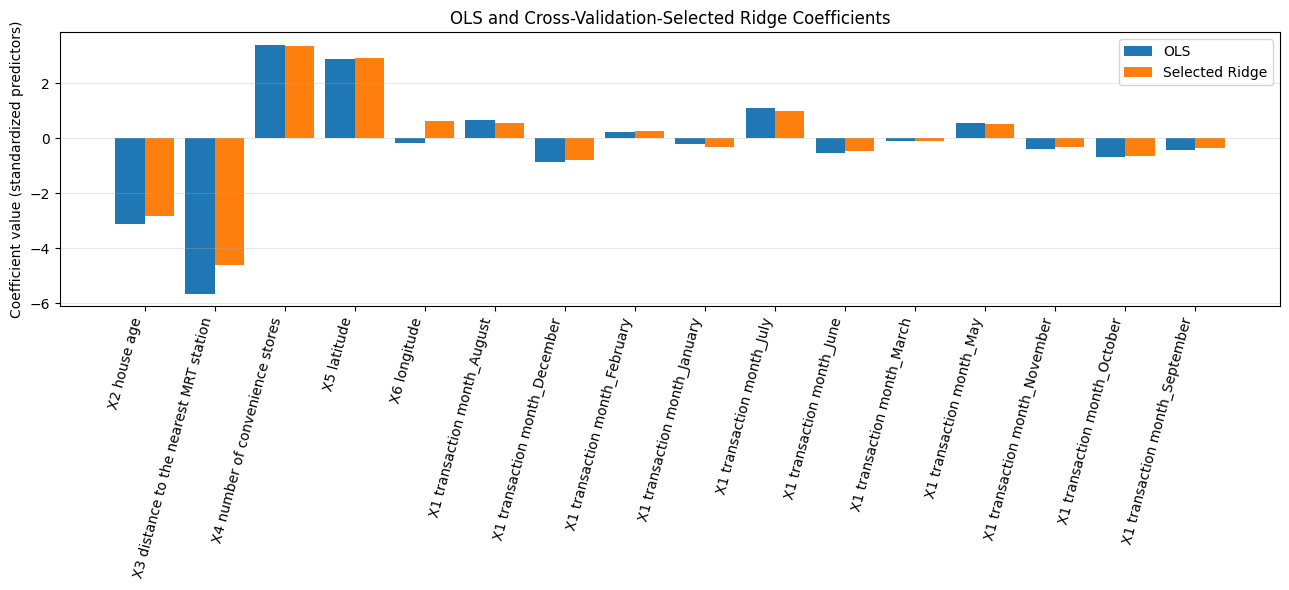

In [29]:
# plot ols versus selected ridge coefficients

plot_coefficients = coefficient_comparison.iloc[1:].copy()
positions = np.arange(len(plot_coefficients))
width = 0.42

plt.figure(figsize=(13, 6))
plt.bar(positions - width / 2, plot_coefficients["OLS_Coefficient"], width, label="OLS")
plt.bar(positions + width / 2, plot_coefficients["Ridge_Coefficient"], width, label="Selected Ridge")
plt.xticks(positions, plot_coefficients["Feature"], rotation=75, ha="right")
plt.ylabel("Coefficient value (standardized predictors)")
plt.title("OLS and Cross-Validation-Selected Ridge Coefficients")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(figures / "ridge_cv_selected_coefficient_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

,Actual,Predicted_Ridge,Residual
0,37.9,45.703424,-7.803424
1,42.2,46.236893,-4.036893
2,47.3,49.404197,-2.104197
3,54.8,50.058343,4.741657
4,43.1,46.472318,-3.372318
5,32.1,31.997767,0.102233
6,40.3,40.135297,0.164703
7,46.7,44.260381,2.439619
8,18.8,11.903846,6.896154
9,22.1,31.811116,-9.711116


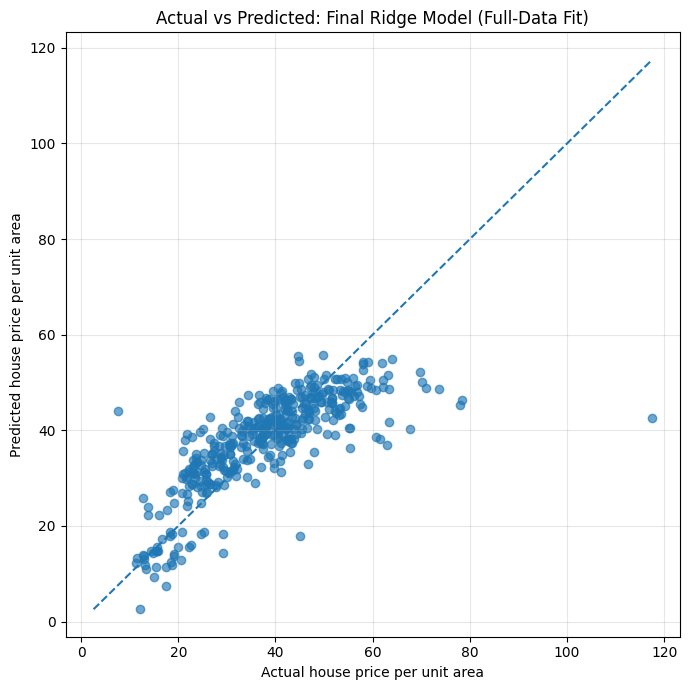

In [30]:
# inspect predictions from the final full data ridge fit

prediction_table = pd.DataFrame({
    "Actual": y,
    "Predicted_Ridge": final_predictions,
    "Residual": y - final_predictions,
})
display(prediction_table.head(10))

plt.figure(figsize=(7, 7))
plt.scatter(y, final_predictions, alpha=0.65)
minimum = min(y.min(), final_predictions.min())
maximum = max(y.max(), final_predictions.max())
plt.plot([minimum, maximum], [minimum, maximum], linestyle="--")
plt.xlabel("Actual house price per unit area")
plt.ylabel("Predicted house price per unit area")
plt.title("Actual vs Predicted: Final Ridge Model (Full-Data Fit)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(figures / "ridge_cv_final_actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()

In [31]:
# save cross-validation tables

fold_results.to_csv(tables / "ridge_cv_fold_results.csv", index=False)
cv_summary.to_csv(tables / "ridge_cv_summary.csv", index=False)
nearby_lambda_summary.to_csv(tables / "ridge_cv_selected_lambda_neighborhood.csv", index=False)
ols_ridge_cv_folds.to_csv(tables / "ridge_cv_ols_ridge_fold_comparison.csv", index=False)
ols_ridge_cv_summary.to_csv(tables / "ridge_cv_ols_ridge_summary.csv", index=False)

print("Cross-validation tables saved.")

Cross-validation tables saved.


In [32]:
# save final model tables

final_coefficient_table.to_csv(tables / "ridge_cv_final_coefficients.csv", index=False)
coefficient_comparison.to_csv(tables / "ridge_cv_ols_ridge_coefficients.csv", index=False)
full_data_comparison.to_csv(tables / "ridge_cv_full_data_training_metrics.csv", index=False)
prediction_table.to_csv(tables / "ridge_cv_final_predictions.csv", index=False)

final_model_summary = pd.DataFrame([{
    "Selected_Lambda": best_lambda,
    "CV_MSE_Mean": best_row["MSE_mean"],
    "CV_MSE_Std": best_row["MSE_std"],
    "CV_RMSE_Mean": best_row["RMSE_mean"],
    "CV_MAE_Mean": best_row["MAE_mean"],
    "CV_R2_Mean": best_row["R2_mean"],
    "Full_Data_Training_MSE": final_training_metrics["MSE"],
    "Full_Data_Training_RMSE": final_training_metrics["RMSE"],
    "Full_Data_Training_MAE": final_training_metrics["MAE"],
    "Full_Data_Training_R2": final_training_metrics["R2"],
    "Number_of_Folds": N_SPLITS,
    "Random_State": RANDOM_STATE,
}])
final_model_summary.to_csv(tables / "ridge_cv_final_model_summary.csv", index=False)

display(final_model_summary)
print("Final model tables saved.")

,Selected_Lambda,CV_MSE_Mean,CV_MSE_Std,CV_RMSE_Mean,CV_MAE_Mean,CV_R2_Mean,Full_Data_Training_MSE,Full_Data_Training_RMSE,Full_Data_Training_MAE,Full_Data_Training_R2,Number_of_Folds,Random_State
0,35.297073,86.416203,35.126381,9.167386,6.447812,0.536094,75.446725,8.686007,6.057998,0.591494,5,42


Final model tables saved.


## 29. Save the Full-Data Scaling Parameters

In [33]:
# save the full-data scaling parameters

scaling_parameters = pd.DataFrame({
    "Feature": feature_names,
    "Full_Data_Mean": full_means,
    "Full_Data_Standard_Deviation": full_scales,
})
scaling_parameters.to_csv(tables / "ridge_cv_full_data_scaling_parameters.csv", index=False)
display(scaling_parameters)

,Feature,Full_Data_Mean,Full_Data_Standard_Deviation
0,X2 house age,17.712560,11.378717
1,X3 distance to the nearest MRT station,1083.885689,1260.584387
2,X4 number of convenience stores,4.094203,2.942002
3,X5 latitude,24.969030,0.012395
4,X6 longitude,121.533361,0.015329
5,X1 transaction month_August,0.055556,0.229061
6,X1 transaction month_December,0.091787,0.288726
7,X1 transaction month_February,0.111111,0.314270
8,X1 transaction month_January,0.067633,0.251115
9,X1 transaction month_July,0.113527,0.317235


In [34]:
# final numerical checks

print("All final numerical checks passed.")
print("Selected lambda:", best_lambda)
print("Cross-validation mean MSE:", best_cv_mse)
print("Final Ridge coefficient norm (excluding intercept):", ridge_norm)

All final numerical checks passed.
Selected lambda: 35.2970730273065
Cross-validation mean MSE: 86.41620264876255
Final Ridge coefficient norm (excluding intercept): 7.233946335209015


## 31. Interpretation and Conclusion

The five-fold cross-validation procedure evaluates each candidate λ on observations not used to fit that fold's model. Standardization is recalculated within every training fold, so validation observations do not influence the scaling parameters. The λ with the smallest mean validation MSE is selected.

After selection, the scaler and Ridge model are refitted using the complete dataset. The full-data training metrics and predictions are reported for model description; they should not be interpreted as an independent estimate of generalization performance. The fold-level and aggregated validation results provide the cross-validation evidence for λ selection.

The selected λ should be carried forward to Notebook 16. If Notebook 16 uses a separate holdout test set, all preprocessing and model fitting for that final evaluation must be learned from the training partition only.